# IPR phase diagram of the XXZ chain in a longitudinal field

This notebook builds the $(\Delta, h)$ phase diagram of the periodic spin-1/2 XXZ
chain at $L=14$ from the raw field sweep, and saves the paper figure under
`Paper plots Heisenberg/`.

The Hamiltonian is written with Pauli operators,

$$H = \sum_i \left[\sigma^x_i \sigma^x_{i+1} + \sigma^y_i \sigma^y_{i+1}
      + \Delta\, \sigma^z_i \sigma^z_{i+1}\right] + h \sum_i \sigma^z_i .$$

The colour field is the basis contrast

$$\log_{10}\!\left(\mathrm{IPR}_Z / \mathrm{IPR}_{XY}\right),$$

with $\mathrm{IPR}_Z$ measured in the computational basis and $\mathrm{IPR}_{XY}$ in
the momentum-occupation basis of the XX model. The colour map is the repository's
shared `IPR_GRAM_CMAP` from `scripts/plot_gram_matrices.py` (cream to orange to
green), with the orange-to-green switch shifted towards the sign change of the
contrast: cream and orange where the momentum basis is more localized, green where
the $Z$ basis is.

Overlaid are the numerical sign changes of the contrast and the Bethe-ansatz
critical fields. **Note the factor of two**: $h_{c2} = 1 + \Delta$ and the $h_{c1}$
sum are quoted for the spin-1/2 normalization
$H = \sum_i [\mathbf{S}_i\cdot\mathbf{S}_{i+1}\ldots] + h_{\mathrm{BA}}\sum_i S^z_i$,
whereas the data uses Pauli operators. The two are related by
$h_{\mathrm{data}} = 2\,h_{\mathrm{BA}}$, confirmed against the measured saturation
field ($h_{\mathrm{sat}} \approx 2(1+\Delta)$ in data units).

The $h$ axis increases **downward**, and the grid is indexed with $h$ descending
throughout, both carried over from the original analysis.

In [1]:
from __future__ import annotations

from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgb
from matplotlib.ticker import AutoMinorLocator
import numpy as np
import pandas as pd


def find_repo_root(start: Path | None = None) -> Path:
    """Find the project root so notebook imports work from any working directory."""
    start = Path.cwd() if start is None else Path(start).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "scripts" / "data_config.py").is_file():
            return candidate
    raise FileNotFoundError("Could not find repository root containing scripts/data_config.py.")


REPO_ROOT = find_repo_root()
SCRIPTS_DIR = REPO_ROOT / "scripts"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

from plot_gram_matrices import IPR_GRAM_CMAP
from plot_ipr_curves import set_ipr_plot_style

NOTEBOOK_DIR = REPO_ROOT / "Paper Analysis" / "Heisenberg"
PLOTS_DIR = NOTEBOOK_DIR / "Paper plots Heisenberg"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

SWEEP_CSV = (REPO_ROOT / "Data" / "Raw" / "Data Heisenberg" / "L=14_with_field"
             / "ipr_field_sweep_L=14.csv")

CONTRAST_LABEL = r"$\log_{10}(\mathrm{IPR}_{Z} / \mathrm{IPR}_{XY})$"
CONTRAST_TICKS = [-3, -2, -1, 0, 1]
OBSERVABLES = ("ipr_z", "ipr_xy", "structure_factor_0", "structure_factor_pi")

GRID_STEP = 0.2          # spacing of the (Delta, h) sweep
AXIS_TICKS = (-4, -2, 0, 2, 4)
MINOR_SUBDIVISIONS = 4   # 3 minor ticks between majors

# Fraction of the colour range at which orange gives way to green. The shared
# IPR_GRAM_CMAP puts that switch at 5/6 of the range, which suits Gram matrices on
# [0, 1] but not a log ratio spanning roughly -3.2 to 1.15. Shifting it to 0.67
# places the switch near the sign change of the contrast.
GRAM_TRANSITION_POINT = 0.67

# Field unit conversion between the Pauli-normalized data and Bethe-ansatz results.
BA_FIELD_SCALE = 2.0

# Below this anisotropy the chain is ferromagnetic, both IPRs are ~1 and the contrast
# is zero up to degenerate-state scatter. Flattening it is cosmetic, not a correction.
FM_MASK_DELTA = -1.0

# Phase labels, carried over from the original analysis, which specified them in
# grid-index space with Delta = 0.2x - 5.1 and h = 5.1 - 0.2y.
PHASE_LABELS = (
    (-2.3, 2.1, "Ferromagnetic"),
    (0.7, 1.1, "Paramagnetic"),
    (3.7, 0.1, "Anti-\nFerromagnetic"),
)

set_ipr_plot_style()
plt.rcParams.update({"figure.dpi": 140, "savefig.dpi": 300})


def shifted_gram_cmap(transition_point: float = GRAM_TRANSITION_POINT,
                      n_colors: int = 512) -> LinearSegmentedColormap:
    """Rebuild the shared IPR_GRAM_CMAP with a movable orange-to-green switch.

    The four stops are sampled from `IPR_GRAM_CMAP` itself so the palette cannot
    drift from `scripts/plot_gram_matrices.py`. The switch colour is the 50/50 blend
    of deep orange and green, which keeps the seam from reading as a hard edge.
    """
    if not 0.0 < transition_point < 1.0:
        raise ValueError(f"transition_point must lie in (0, 1), got {transition_point}")

    cream, light_orange, deep_orange, green = (IPR_GRAM_CMAP(x) for x in (0.0, 1 / 3, 2 / 3, 1.0))
    mid_color = tuple(0.5 * np.asarray(to_rgb(deep_orange)) + 0.5 * np.asarray(to_rgb(green)))

    stops = [
        (0.0, cream),
        (transition_point * 0.6, light_orange),
        (transition_point * 0.8, deep_orange),
        (transition_point, mid_color),
        (transition_point + (1.0 - transition_point) * 0.3, green),
        (1.0, green),
    ]
    return LinearSegmentedColormap.from_list("ipr_gram_shifted", stops, N=n_colors)


IPR_CONTRAST_CMAP = shifted_gram_cmap()


def save_pdf(fig, stem: str) -> Path:
    path = PLOTS_DIR / f"{stem}.pdf"
    fig.savefig(path, bbox_inches="tight")
    return path

## Loading the sweep

In [2]:
def load_field_sweep(path: Path = SWEEP_CSV) -> pd.DataFrame:
    """Load the (Delta, h) sweep and validate the columns the figure needs."""
    if not path.is_file():
        raise FileNotFoundError(
            f"{path} not found. Regenerate it with "
            "data_generation/generate_data_heisenberg_field.py"
        )
    # round_trip is the only pandas parser that recovers float64 exactly;
    # the default loses an ulp on most values.
    df = pd.read_csv(path, float_precision="round_trip")
    missing = set(OBSERVABLES).difference(df.columns)
    if missing:
        raise ValueError(f"{path.name} is missing required columns: {sorted(missing)}")
    for column in OBSERVABLES:
        df[column] = pd.to_numeric(df[column], errors="coerce")
    return df.dropna(subset=list(OBSERVABLES))


def sweep_arrays(df: pd.DataFrame) -> tuple[np.ndarray, np.ndarray, dict[str, np.ndarray]]:
    """Return ascending Delta, descending h, and each observable as a [Delta, h] array.

    The descending-h ordering and the [Delta, h] index order are those of the original
    analysis, so the boundary scan below can be checked against its published indices.
    """
    grids = {}
    delta = h_desc = None
    for name in OBSERVABLES:
        pivot = df.pivot(index="h", columns="delta", values=name).sort_index()
        if pivot.isna().to_numpy().any():
            raise ValueError("The (Delta, h) grid has holes; expected a full sweep.")
        delta = pivot.columns.to_numpy(dtype=float)
        h_desc = pivot.index.to_numpy(dtype=float)[::-1]
        grids[name] = pivot.to_numpy()[::-1].T
    return delta, h_desc, grids


def contrast_grid(grids: dict[str, np.ndarray], delta: np.ndarray,
                  mask_delta: float | None = FM_MASK_DELTA) -> np.ndarray:
    """log10(IPR_Z / IPR_XY) as a [h, Delta] array ready for pcolormesh."""
    if (grids["ipr_z"] <= 0).any() or (grids["ipr_xy"] <= 0).any():
        raise ValueError("Non-positive IPR values found; cannot take a log ratio.")
    contrast = np.log10(grids["ipr_z"] / grids["ipr_xy"]).T
    if mask_delta is not None:
        contrast[:, delta < mask_delta] = 0.0
    return contrast


sweep = load_field_sweep()
delta, h_desc, grids = sweep_arrays(sweep)
contrast = contrast_grid(grids, delta)
print(f"grid: {delta.size} Delta x {h_desc.size} h")
print(f"Delta in [{delta.min():g}, {delta.max():g}], h in [{h_desc.min():g}, {h_desc.max():g}]")
print(f"contrast range: {np.nanmin(contrast):.2f} .. {np.nanmax(contrast):.2f}")

grid: 51 Delta x 51 h
Delta in [-5, 5], h in [-5, 5]
contrast range: -3.20 .. 1.15


## Critical fields and the numerical boundary

`hc2` is the saturation field and `hc1` the lower critical field of the gapped
antiferromagnet, both in Bethe-ansatz units, converted by `BA_FIELD_SCALE` when
plotted.

The numerical boundary is the first sign change of $\ln(\mathrm{IPR}_Z/\mathrm{IPR}_{XY})$
scanning in $\Delta$ from each edge, evaluated on the **unmasked** ratio. The two
branches are offset half a grid step outward so they bracket the cells they were
found in, as in the original analysis.

In [3]:
def hc2(delta: np.ndarray | float) -> np.ndarray:
    """Saturation field of the XXZ chain, h_c2 = 1 + Delta (Bethe-ansatz units)."""
    return 1.0 + np.asarray(delta, dtype=float)


def hc1(delta: np.ndarray | float, cutoff: int = 100) -> np.ndarray:
    """Lower critical field of the gapped antiferromagnet (Bethe-ansatz units).

    Zero for Delta <= 1, where there is no gap to overcome. Above it,
    h_c1 = sinh(eta) * sum_k (-1)^k / cosh(k eta) with eta = arccosh(Delta).
    """
    delta = np.atleast_1d(np.asarray(delta, dtype=float))
    out = np.zeros_like(delta)
    ks = np.arange(-cutoff, cutoff + 1)
    for i, d in enumerate(delta):
        if d > 1.0:
            eta = np.arccosh(d)
            out[i] = np.sinh(eta) * np.sum((-1.0) ** ks / np.cosh(ks * eta))
    return out


# At h = 0 the inward scan stops one cell early, at Delta = -0.8 instead of the
# Delta = -1 apex the surrounding fields converge on. The original analysis pinned it
# by hand; kept here so the published boundary is unchanged. Keys are h indices.
INNER_BOUNDARY_OVERRIDE = {25: 20}


def contrast_sign_boundaries(grids: dict[str, np.ndarray], delta: np.ndarray
                            ) -> tuple[np.ndarray, np.ndarray]:
    """Anisotropy of the first contrast sign change, per field, from each edge.

    Returns (outer, inner) in Delta, each offset half a grid step away from the cell
    centre so the pair brackets the transition rather than sitting on one side of it.
    """
    ratio = np.log(grids["ipr_z"] / grids["ipr_xy"])
    n_delta, n_h = ratio.shape

    outer_idx = np.empty(n_h, dtype=int)
    inner_idx = np.empty(n_h, dtype=int)
    for j in range(n_h):
        descending = np.flatnonzero(ratio[::-1, j] < 0.0)
        ascending = np.flatnonzero(ratio[:, j] < -1e-4)
        if not descending.size or not ascending.size:
            raise ValueError(f"No contrast sign change at h index {j}.")
        outer_idx[j] = n_delta - 1 - descending[0]
        inner_idx[j] = ascending[0]

    for j, forced in INNER_BOUNDARY_OVERRIDE.items():
        inner_idx[j] = forced

    half_step = GRID_STEP / 2.0
    return delta[outer_idx] + half_step, delta[inner_idx] - half_step


outer_boundary, inner_boundary = contrast_sign_boundaries(grids, delta)
print(f"outer branch spans Delta {outer_boundary.min():.1f} .. {outer_boundary.max():.1f}")
print(f"inner branch spans Delta {inner_boundary.min():.1f} .. {inner_boundary.max():.1f}")

outer branch spans Delta 2.3 .. 4.1
inner branch spans Delta -1.1 .. 1.5


## Figure

saved: heisenberg_L14_field_ipr_phase_diagram.pdf


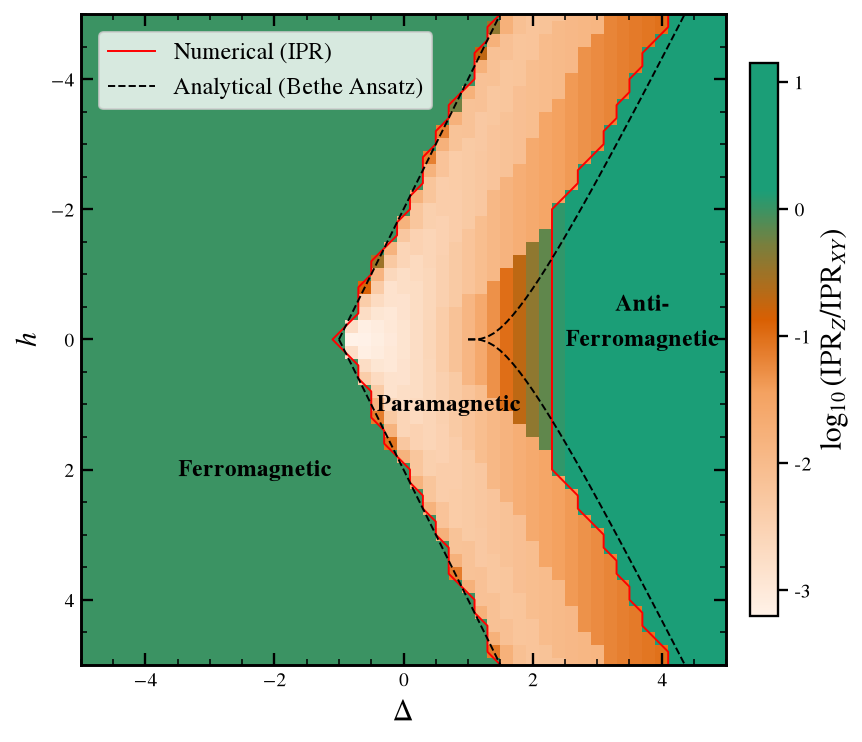

In [4]:
def plot_field_phase_diagram(delta: np.ndarray, h_desc: np.ndarray, contrast: np.ndarray,
                             outer_boundary: np.ndarray, inner_boundary: np.ndarray,
                             annotate: bool = True) -> tuple[plt.Figure, plt.Axes]:
    """Draw the basis-contrast phase diagram with numerical and analytic boundaries."""
    fig, ax = plt.subplots(figsize=(6.4, 5.4))

    norm = Normalize(vmin=float(np.nanmin(contrast)), vmax=float(np.nanmax(contrast)))
    mesh = ax.pcolormesh(delta, h_desc, contrast, cmap=IPR_CONTRAST_CMAP, norm=norm,
                         shading="nearest", rasterized=True)

    cbar = fig.colorbar(mesh, ax=ax, pad=0.03, shrink=0.85)
    cbar.set_label(CONTRAST_LABEL)
    cbar.outline.set_edgecolor("black")
    cbar.outline.set_linewidth(1.2)
    cbar.ax.tick_params(axis="both", direction="out", colors="black", width=1.2, length=5)
    cbar.set_ticks(CONTRAST_TICKS)
    cbar.ax.set_yticklabels([str(t) for t in CONTRAST_TICKS])

    ax.plot(outer_boundary, h_desc, color="red", linewidth=1, label="Numerical (IPR)")
    ax.plot(inner_boundary, h_desc, color="red", linewidth=1)

    d_c2 = np.linspace(-1.0, 2.0, 31)
    d_c1 = np.linspace(1.0, 5.0, 41)
    for sign in (+1.0, -1.0):
        ax.plot(d_c2, sign * BA_FIELD_SCALE * hc2(d_c2), color="black", linestyle="--",
                linewidth=1,
                label="Analytical (Bethe Ansatz)" if sign > 0 else None)
        ax.plot(d_c1, sign * BA_FIELD_SCALE * hc1(d_c1), color="black", linestyle="--",
                linewidth=1)

    ax.set_xlabel(r"$\Delta$")
    ax.set_ylabel(r"$h$")
    ax.set_xlim(delta.min(), delta.max())
    ax.set_ylim(h_desc.max(), h_desc.min())   # h increases downward

    ax.set_xticks(AXIS_TICKS)
    ax.set_yticks(AXIS_TICKS)
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_minor_locator(AutoMinorLocator(MINOR_SUBDIVISIONS))
    for which, width, length in (("major", 1.2, 6), ("minor", 0.8, 3)):
        ax.tick_params(axis="both", which=which, direction="in", top=True, right=True,
                       labeltop=False, labelright=False, width=width, length=length,
                       color="black")
    # The rcParam default "axes.axisbelow" is "line", putting the axis at zorder 1.5,
    # below plotted lines at 2, so the inward ticks get overdrawn by the boundary
    # curves. False raises it to 2.5: above the lines, below annotations and legend.
    ax.set_axisbelow(False)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color("black")
        spine.set_linewidth(1.5)

    if annotate:
        for x, y, text in PHASE_LABELS:
            ax.text(x, y, text, fontsize=12, fontweight="bold", ha="center")

    ax.legend(loc="upper left", bbox_to_anchor=(0.01, 0.99))
    fig.tight_layout()
    return fig, ax


fig, ax = plot_field_phase_diagram(delta, h_desc, contrast, outer_boundary, inner_boundary)
print("saved:", save_pdf(fig, "heisenberg_L14_field_ipr_phase_diagram").name)